# Week 1 — FinTech Taxonomy & the Pakistani Ecosystem
**Course:** FinTech (AF 705) · **Student:** Noureen Mushtaq · **Instructor:** Dr. Nosherwan Khan




## 1. Setup and data loading


In [ ]:
import re, glob
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_rows', 60)

KAGGLE_DATASET = "deepcontractor/unicorn-companies-dataset"

def load_kaggle():
    import kagglehub
    path = kagglehub.dataset_download(KAGGLE_DATASET)
    csv = glob.glob(f"{path}/**/*.csv", recursive=True)[0]
    df = pd.read_csv(csv, encoding="latin-1")
    df.columns = [c.strip() for c in df.columns]
    return df

# Fallback snapshot: real FinTech unicorns (approximate valuations, US$ bn) in the same column layout
FALLBACK = [
 ("Stripe",95,"United States","Fintech"),("Klarna",45.6,"Sweden","Fintech"),("Checkout.com",40,"United Kingdom","Fintech"),
 ("Revolut",33,"United Kingdom","Fintech"),("FTX",32,"Bahamas","Fintech"),("Chime",25,"United States","Fintech"),
 ("Ripple",15,"United States","Fintech"),("Blockchain.com",14,"United Kingdom","Fintech"),("Plaid",13.4,"United States","Fintech"),
 ("Brex",12.3,"United States","Fintech"),("Rapyd",15,"United Kingdom","Fintech"),("Digital Currency Group",10,"United States","Fintech"),
 ("Kraken",10,"United States","Fintech"),("Alchemy",10.2,"United States","Fintech"),("Chainalysis",8.6,"United States","Fintech"),
 ("N26",9,"Germany","Fintech"),("Fireblocks",8,"United States","Fintech"),("Tipalti",8.3,"United States","Fintech"),
 ("Razorpay",7.5,"India","Fintech"),("Consensys",7,"United States","Fintech"),("Ramp",8.1,"United States","Fintech"),
 ("Airwallex",5.5,"Australia","Fintech"),("Monzo",4.5,"United Kingdom","Fintech"),("Wealthsimple",5,"Canada","Fintech"),
 ("Groww",3,"India","Fintech"),("Carta",7.4,"United States","Fintech"),("Trade Republic",5.3,"Germany","Fintech"),
 ("Upgrade",6.3,"United States","Fintech"),("Tabby",1.5,"United Arab Emirates","Fintech"),("Zilch",2,"United Kingdom","Fintech"),
 ("Sunbit",1.1,"United States","Fintech"),("Next Insurance",4,"United States","Fintech"),("wefox",4.5,"Germany","Fintech"),
 ("Acko General Insurance",1.1,"India","Fintech"),("Coalition",5,"United States","Fintech"),("Socure",4.5,"United States","Fintech"),
 ("Alloy",1.6,"United States","Fintech"),("Feedzai",1,"United States","Fintech"),("Pine Labs",5,"India","Fintech"),
 ("BharatPe",2.9,"India","Fintech"),("Zepz",5,"United Kingdom","Fintech"),("Scalable Capital",1.4,"Germany","Fintech"),
]

try:
    raw = load_kaggle()
    SOURCE = f"Kaggle: {KAGGLE_DATASET}"
except Exception as e:
    print("Kaggle download failed, using built-in snapshot ->", e)
    raw = pd.DataFrame(FALLBACK, columns=["Company","Valuation ($B)","Country","Industry"])
    SOURCE = "built-in snapshot"
print("Source:", SOURCE, "| shape:", raw.shape)
raw.head()

100%|██████████| 41.5k/41.5k [00:00<00:00, 32.8MB/s]

Extracting files...
Source: Kaggle: deepcontractor/unicorn-companies-dataset | shape: (1037, 13)


,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Inverstors,Founded Year,Total Raised,Financial Stage,Investors Count,Deal Terms,Portfolio Exits
0,Bytedance,$140,4/7/2017,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S...",2012.0,$7.44B,IPO,28.0,8.0,5.0
1,SpaceX,$100.3,12/1/2012,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen...",2002.0,$6.874B,NaN,29.0,12.0,NaN
2,Stripe,$95,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",2010.0,$2.901B,Asset,39.0,12.0,1.0
3,Klarna,$45.6,12/12/2011,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita...",2005.0,$3.472B,Acquired,56.0,13.0,1.0
4,Epic Games,$42,10/26/2018,United States,Cary,Other,"Tencent Holdings, KKR, Smash Ventures",1991.0,$4.377B,Acquired,25.0,5.0,2.0


### Keep only FinTech companies
The dataset has an `Industry` column; we keep rows labelled *Fintech*.

In [ ]:
ind = raw["Industry"].astype(str).str.strip().str.lower()
fin = raw[ind.str.contains("fintech")].copy().reset_index(drop=True)
print("FinTech companies in dataset:", len(fin))
fin.head(10)

FinTech companies in dataset: 205


,Company,Valuation ($B),Date Joined,Country,City,Industry,Select Inverstors,Founded Year,Total Raised,Financial Stage,Investors Count,Deal Terms,Portfolio Exits
0,Stripe,$95,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",2010.0,$2.901B,Asset,39.0,12.0,1.0
1,Klarna,$45.6,12/12/2011,Sweden,Stockholm,Fintech,"Institutional Venture Partners, Sequoia Capita...",2005.0,$3.472B,Acquired,56.0,13.0,1.0
2,Checkout.com,$40,5/2/2019,United Kingdom,London,Fintech,"Tiger Global Management, Insight Partners, DST...",2012.0,$1.83B,NaN,15.0,4.0,NaN
3,Revolut,$33,4/26/2018,United Kingdom,London,Fintech,"index Ventures, DST Global, Ribbit Capital",2015.0,$1.716B,NaN,31.0,6.0,NaN
4,Chime,$25,3/5/2019,United States,San Francisco,Fintech,"Forerunner Ventures, Crosslink Capital, Homebrew",2013.0,$2.599B,Divestiture,24.0,9.0,1.0
5,Ripple,$15,12/20/2019,United States,San Francisco,Fintech,"IDG Capital, Venture51, Lightspeed Venture Par...",2012.0,$293.9M,Acq,34.0,5.0,1.0
6,Plaid,$13.4,12/11/2018,United States,San Francisco,Fintech,"New Enterprise Associates, Spar Capital, Index...",2012.0,$734.8M,NaN,24.0,5.0,NaN
7,Brex,$12.3,10/5/2018,United States,San Francisco,Fintech,"DST Global, Ribbit Capital, Greenoaks Capital ...",2017.0,$1.49B,NaN,28.0,7.0,NaN
8,Bolt,$11,10/8/2021,United States,San Francisco,Fintech,"Activant Capital, Tribe Capital, General Atlantic",2014.0,$963M,NaN,37.0,3.0,NaN
9,Alchemy,$10.2,10/28/2021,United States,San Francisco,Fintech,"DFJ Growth Fund, Coatue Management, Addition",2017.0,$545M,NaN,27.0,3.0,NaN


## 2. Classification into the seven-category taxonomy
The dataset only says *Fintech*, so each company is classified by hand based on its **core revenue-generating product** (what customers mainly use it for). A lookup table of company → category is applied to the DataFrame as a new column `Taxonomy`. Companies not in the lookup are marked *Unclassified* and excluded from the analysis.

In [ ]:
TAXONOMY = {
 # Payments & Digital Wallets
 "Stripe":"Payments & Digital Wallets","Checkout.com":"Payments & Digital Wallets","Rapyd":"Payments & Digital Wallets",
 "Airwallex":"Payments & Digital Wallets","Razorpay":"Payments & Digital Wallets","Pine Labs":"Payments & Digital Wallets",
 "BharatPe":"Payments & Digital Wallets","Tipalti":"Payments & Digital Wallets","Zepz":"Payments & Digital Wallets",
 "Plaid":"Payments & Digital Wallets","Ramp":"Payments & Digital Wallets","Bolt":"Payments & Digital Wallets",
 "Nium":"Payments & Digital Wallets","SumUp":"Payments & Digital Wallets","Mollie":"Payments & Digital Wallets",
 "Flutterwave":"Payments & Digital Wallets","Paystack":"Payments & Digital Wallets","Payoneer":"Payments & Digital Wallets",
 # Digital Banking & Neobanks
 "Revolut":"Digital Banking & Neobanks","Chime":"Digital Banking & Neobanks","N26":"Digital Banking & Neobanks",
 "Monzo":"Digital Banking & Neobanks","Brex":"Digital Banking & Neobanks","Current":"Digital Banking & Neobanks",
 "Varo Bank":"Digital Banking & Neobanks","Starling Bank":"Digital Banking & Neobanks","Tide":"Digital Banking & Neobanks",
 # Lending Tech & BNPL
 "Klarna":"Lending Tech & BNPL","Upgrade":"Lending Tech & BNPL","Tabby":"Lending Tech & BNPL","Tamara":"Lending Tech & BNPL",
 "Zilch":"Lending Tech & BNPL","Sunbit":"Lending Tech & BNPL","Better.com":"Lending Tech & BNPL","Kueski":"Lending Tech & BNPL",
 # WealthTech & Robo-Advisory
 "Wealthsimple":"WealthTech & Robo-Advisory","Groww":"WealthTech & Robo-Advisory","Trade Republic":"WealthTech & Robo-Advisory",
 "Scalable Capital":"WealthTech & Robo-Advisory","Carta":"WealthTech & Robo-Advisory","Acorns":"WealthTech & Robo-Advisory",
 "Upstox":"WealthTech & Robo-Advisory","Public.com":"WealthTech & Robo-Advisory",
 # InsurTech
 "Next Insurance":"InsurTech","wefox":"InsurTech","Acko General Insurance":"InsurTech","Coalition":"InsurTech",
 "Digit Insurance":"InsurTech","Ethos":"InsurTech","Clearcover":"InsurTech",
 # Blockchain & Crypto
 "FTX":"Blockchain & Crypto","Ripple":"Blockchain & Crypto","Blockchain.com":"Blockchain & Crypto","Kraken":"Blockchain & Crypto",
 "Digital Currency Group":"Blockchain & Crypto","Alchemy":"Blockchain & Crypto","Fireblocks":"Blockchain & Crypto",
 "Consensys":"Blockchain & Crypto","MoonPay":"Blockchain & Crypto","Ledger":"Blockchain & Crypto","Circle":"Blockchain & Crypto",
 # RegTech
 "Chainalysis":"RegTech","Socure":"RegTech","Alloy":"RegTech","Feedzai":"RegTech","Persona":"RegTech",
}

norm = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
lookup = {norm(k): v for k, v in TAXONOMY.items()}
fin["Taxonomy"] = fin["Company"].map(lambda c: lookup.get(norm(c), "Unclassified"))

classified = fin[fin["Taxonomy"] != "Unclassified"].copy()
print("Classified:", len(classified), "of", len(fin), "FinTech companies")
assert len(classified) >= 25, "Need at least 25 classified companies"
classified[["Company", "Country", "Valuation ($B)", "Taxonomy"]].sort_values("Taxonomy").reset_index(drop=True)

Classified: 49 of 205 FinTech companies


,Company,Country,Valuation ($B),Taxonomy
0,Circle,United States,$3,Blockchain & Crypto
1,MoonPay,United States,$3.4,Blockchain & Crypto
2,Kraken,United States,$2.92,Blockchain & Crypto
3,Fireblocks,United States,$8,Blockchain & Crypto
4,Blockchain.com,United Kingdom,$5.2,Blockchain & Crypto
5,Ripple,United States,$15,Blockchain & Crypto
6,ConsenSys,United States,$3.2,Blockchain & Crypto
7,Alchemy,United States,$10.2,Blockchain & Crypto
8,Starling Bank,United Kingdom,$1.95,Digital Banking & Neobanks
9,N26,Germany,$9.23,Digital Banking & Neobanks


### Justification for three non-obvious classifications
- **Brex → Digital Banking & Neobanks (not Payments or Lending).** Brex started as a corporate charge card, which looks like lending or payments. But it now gives startups a full business account — cash management, cards, bill pay and spend control in one app with no branch — which is the neobank model for businesses, so its *core relationship* with the customer is banking.
- **Chainalysis → RegTech (not Blockchain & Crypto).** It works entirely with blockchain data, but it does not issue tokens, run an exchange or hold crypto. Its customers are banks, exchanges and governments who use it for AML compliance and investigations, so its purpose is regulatory compliance — the definition of RegTech.
- **Plaid → Payments & Digital Wallets (not RegTech or Digital Banking).** Plaid is open-banking plumbing: an API that connects apps to users' bank accounts. It holds no deposits, so it is not a bank. Its main use is to enable account-to-account payments and money movement inside other apps (e.g., Venmo), so it fits best with Payments infrastructure.

## 3. Pakistani apps comparison table

In [ ]:
pk = pd.DataFrame([
 ["JazzCash", "Payments & Digital Wallets", "Branchless banking / mobile wallet of Mobilink Microfinance Bank (SBP)",
  "Launched 2012; one of Pakistan's largest mobile wallets with a huge agent network"],
 ["Easypaisa / Easypaisa Bank", "Digital Banking & Neobanks", "SBP digital retail bank licence (Jan 2025)",
  "Wallet launched 2009 by Telenor; became Pakistan's first licensed digital retail bank"],
 ["NayaPay", "Payments & Digital Wallets", "Electronic Money Institution (EMI), SBP",
  "Free wallet + debit card; RAAST-linked instant transfers and merchant payments"],
 ["SadaPay", "Payments & Digital Wallets", "Electronic Money Institution (EMI), SBP",
  "Fee-free Mastercard debit card; acquired by Türkiye's Papara (2023)"],
 ["RAAST", "Payments & Digital Wallets", "Operated by the State Bank of Pakistan",
  "National instant payment system; ~2 bn transactions worth ~Rs 50 trn in 2025"],
 ["Mashreq Bank Pakistan", "Digital Banking & Neobanks", "SBP pilot digital retail bank licence (Feb 2025)",
  "One of five digital bank NOCs issued by SBP in 2022"],
 ["HugoBank", "Digital Banking & Neobanks", "SBP digital bank NOC (2022)",
  "Digital retail bank targeting underbanked individuals and small businesses"],
 ["Abhi", "Lending Tech & BNPL", "SECP-licensed NBFC",
  "Earned-wage access: employees withdraw salary already earned before payday"],
], columns=["App / Platform", "Taxonomy Category", "Regulator / Licence", "Distinguishing Feature"])
pk

,App / Platform,Taxonomy Category,Regulator / Licence,Distinguishing Feature
0,JazzCash,Payments & Digital Wallets,Branchless banking / mobile wallet of Mobilink...,Launched 2012; one of Pakistan's largest mobil...
1,Easypaisa / Easypaisa Bank,Digital Banking & Neobanks,SBP digital retail bank licence (Jan 2025),Wallet launched 2009 by Telenor; became Pakist...
2,NayaPay,Payments & Digital Wallets,"Electronic Money Institution (EMI), SBP",Free wallet + debit card; RAAST-linked instant...
3,SadaPay,Payments & Digital Wallets,"Electronic Money Institution (EMI), SBP",Fee-free Mastercard debit card; acquired by Tü...
4,RAAST,Payments & Digital Wallets,Operated by the State Bank of Pakistan,National instant payment system; ~2 bn transac...
5,Mashreq Bank Pakistan,Digital Banking & Neobanks,SBP pilot digital retail bank licence (Feb 2025),One of five digital bank NOCs issued by SBP in...
6,HugoBank,Digital Banking & Neobanks,SBP digital bank NOC (2022),Digital retail bank targeting underbanked indi...
7,Abhi,Lending Tech & BNPL,SECP-licensed NBFC,Earned-wage access: employees withdraw salary ...


In [ ]:
print("Pakistani apps per category:")
print(pk["Taxonomy Category"].value_counts())

Pakistani apps per category:
Taxonomy Category
Payments & Digital Wallets    4
Digital Banking & Neobanks    3
Lending Tech & BNPL           1
Name: count, dtype: int64


## 4. Visualization — companies per taxonomy category

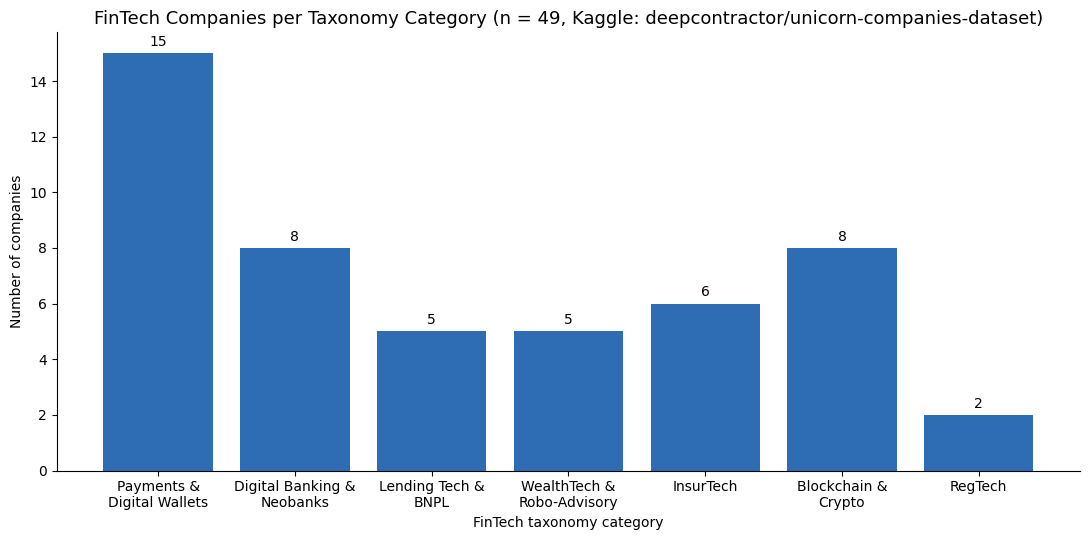

Taxonomy
Payments & Digital Wallets    15
Digital Banking & Neobanks     8
Lending Tech & BNPL            5
WealthTech & Robo-Advisory     5
InsurTech                      6
Blockchain & Crypto            8
RegTech                        2
Name: count, dtype: int64


In [ ]:
order = ["Payments & Digital Wallets","Digital Banking & Neobanks","Lending Tech & BNPL",
         "WealthTech & Robo-Advisory","InsurTech","Blockchain & Crypto","RegTech"]
counts = classified["Taxonomy"].value_counts().reindex(order, fill_value=0)

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(counts.index, counts.values, color="#2E6DB4")
ax.bar_label(bars, padding=3)
ax.set_title(f"FinTech Companies per Taxonomy Category (n = {counts.sum()}, {SOURCE})", fontsize=13)
ax.set_xlabel("FinTech taxonomy category")
ax.set_ylabel("Number of companies")
ax.set_xticks(range(len(order)))
ax.set_xticklabels([c.replace(" & ", " &\n") for c in order], fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(counts)

**Interpretation:** Payments & Digital Wallets is the most represented category in the classified dataset (followed by Blockchain & Crypto), which matches the Week 1 picture of Pakistan, where wallets such as JazzCash, Easypaisa, NayaPay and SadaPay and the RAAST rail make payments the most developed FinTech category — although crypto is far larger globally than it is in Pakistan.

## 5. Reflection
My results broadly **support** the lecture's claim that Payments & Digital Wallets is the most developed FinTech category. In the global unicorn dataset, payments companies such as Stripe, Checkout.com and Razorpay form the largest group, and in my Pakistani table four of the eight platforms are payment-focused. This makes sense: payments are the entry point to finance, they are easy to use without much financial knowledge, and in Pakistan they have been pushed strongly by the SBP through branchless banking rules, EMI licences and RAAST, which processed nearly 2 billion transactions in 2025. However, the dataset also challenges the picture slightly, because globally Blockchain & Crypto is almost as large as payments, while in Pakistan it barely exists as a licensed category.

A clearly **under-represented** category is **WealthTech & Robo-Advisory** — I could not find a large Pakistani robo-advisor comparable to Wealthsimple or Groww. One reason is **market-driven**: most Pakistani households have little investable surplus after inflation, stock market participation is very low, and many savers prefer gold, property or Islamic products they understand. A **regulatory** reason also exists: investment advice and digital brokerage fall under the SECP, whose frameworks for fully digital, algorithm-based advice are still developing, so startups face uncertainty. Until more people are banked and saving digitally, the payments-first pattern is likely to continue, with WealthTech following later.